In [2]:
!python -m pip install numpy pandas matplotlib scikit-learn gensim

Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/59.0 kB ? eta -:--:--
     -------------------- ------------------- 30.7/59.0 kB 1.4 MB/s eta 0:00:01
     -------------------- ------------------- 30.7/59.0 kB 1.4 MB/s eta 0:00:01
     -------------------- ------------------- 30.7/59.0 kB 1.4 MB/s eta 0:00:01
     -------------------- ------------------- 30.7/59.0 kB 1.4 MB/s eta 0:00:01
     -------------------------- ----------- 41.0/59.0 kB 140.9 kB/s eta 0:00:01
     -------------------------------- ----- 51.2/59.0 kB 175.0 kB/s eta 0:00:01
     -------------------------------- ----- 51.2/59.0 kB 175.0 kB/s eta 0:00:01
     -------------------------------- ----- 51.2/59.0 kB 175.0 kB/s eta 0:00:01
     -------------------------------- ----- 51.2/59.0 kB 175.0 kB/s eta 0:00:01
     -------------------------------- ----- 51.2/59.0 kB 175.0 kB/s eta 0:00:01
     -------------------------------- ----- 51.2/5

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.



   ---------------------------------------- 0.1/42.2 MB 744.7 kB/s eta 0:00:57
   ---------------------------------------- 0.1/42.2 MB 653.6 kB/s eta 0:01:05
   ---------------------------------------- 0.1/42.2 MB 653.6 kB/s eta 0:01:05
   ---------------------------------------- 0.1/42.2 MB 653.6 kB/s eta 0:01:05
   ---------------------------------------- 0.2/42.2 MB 586.1 kB/s eta 0:01:12
   ---------------------------------------- 0.2/42.2 MB 586.1 kB/s eta 0:01:12
   ---------------------------------------- 0.2/42.2 MB 586.1 kB/s eta 0:01:12
   ---------------------------------------- 0.2/42.2 MB 533.8 kB/s eta 0:01:19
   ---------------------------------------- 0.3/42.2 MB 561.1 kB/s eta 0:01:15
   ---------------------------------------- 0.3/42.2 MB 527.8 kB/s eta 0:01:20
   ---------------------------------------- 0.3/42.2 MB 519.7 kB/s eta 0:01:21
   ---------------------------------------- 0.3/42.2 MB 503.6 kB/s eta 0:01:24
   ---------------------------------------- 0.3/42.

In [3]:
import numpy
import pandas
import matplotlib
import sklearn
import gensim

print("All libraries installed successfully!")

All libraries installed successfully!


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import cosine_similarity

from gensim.models import Word2Vec

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
categories = [
    'rec.sport.baseball',
    'sci.space',
    'comp.graphics',
    'talk.politics.misc'
]

data = fetch_20newsgroups(
    subset='all',
    categories=categories,
    remove=('headers', 'footers', 'quotes')
)

X = data.data
y = data.target

print("Total Documents:", len(X))
print("Categories:", data.target_names)

Total Documents: 3729
Categories: ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.misc']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Documents:", len(X_train))
print("Testing Documents:", len(X_test))

Training Documents: 2983
Testing Documents: 746


In [8]:
bow = CountVectorizer(max_features=3000)

X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

print("Bag-of-Words Representation:")
print(X_train_bow.shape)
print(X_train_bow.toarray()[:3, :10])

Bag-of-Words Representation:
(2983, 3000)
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


In [9]:
tfidf = TfidfVectorizer(max_features=3000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\nTF-IDF Representation:")
print(X_train_tfidf.shape)
print(X_train_tfidf.toarray()[:3, :10])


TF-IDF Representation:
(2983, 3000)
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [10]:
def tokenize(text):
    return re.findall(r'\b[a-z]+\b', text.lower())


tokenized_sentences = [
    tokenize(text) for text in X_train
]

w2v_model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10
)

print("Word2Vec Model Created Successfully!")
print("Vocabulary Size:", len(w2v_model.wv))

Word2Vec Model Created Successfully!
Vocabulary Size: 16364


In [11]:
def get_document_vector(text):

    words = tokenize(text)

    vectors = [
        w2v_model.wv[word]
        for word in words
        if word in w2v_model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)


X_train_w2v = np.array([
    get_document_vector(text) for text in X_train
])

X_test_w2v = np.array([
    get_document_vector(text) for text in X_test
])

print("Word2Vec Representation:")
print(X_train_w2v.shape)

Word2Vec Representation:
(2983, 100)


In [12]:
text1 = "NASA launched a rocket into space"
text2 = "The spacecraft was sent into orbit"
text3 = "The baseball team won the match"

texts = [text1, text2, text3]

# Bag-of-Words similarity
bow_vectors = bow.transform(texts)
bow_similarity = cosine_similarity(bow_vectors)[0, 1]

# TF-IDF similarity
tfidf_vectors = tfidf.transform(texts)
tfidf_similarity = cosine_similarity(tfidf_vectors)[0, 1]

# Word2Vec similarity
w2v_vectors = np.array([
    get_document_vector(text) for text in texts
])

w2v_similarity = cosine_similarity(w2v_vectors)[0, 1]

print("\nTEXT SIMILARITY COMPARISON")

print("Bag-of-Words:", round(bow_similarity, 4))
print("TF-IDF:", round(tfidf_similarity, 4))
print("Word2Vec:", round(w2v_similarity, 4))


TEXT SIMILARITY COMPARISON
Bag-of-Words: 0.1826
TF-IDF: 0.1069
Word2Vec: 0.6537


In [13]:
models = {
    "Bag-of-Words": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "Word2Vec": (X_train_w2v, X_test_w2v)
}

results = {}

print("\nCLASSIFICATION RESULTS")

for name, (train_data, test_data) in models.items():

    classifier = LogisticRegression(max_iter=1000)

    classifier.fit(train_data, y_train)

    predictions = classifier.predict(test_data)

    accuracy = accuracy_score(y_test, predictions)

    results[name] = accuracy

    print(name, "Accuracy:",
          round(accuracy * 100, 2), "%")


CLASSIFICATION RESULTS
Bag-of-Words Accuracy: 83.51 %
TF-IDF Accuracy: 86.19 %
Word2Vec Accuracy: 78.69 %


In [14]:
comparison = pd.DataFrame({
    "Technique": results.keys(),
    "Accuracy (%)": [
        round(value * 100, 2)
        for value in results.values()
    ]
})

print("\nFINAL COMPARISON TABLE")
print(comparison.to_string(index=False))


FINAL COMPARISON TABLE
   Technique  Accuracy (%)
Bag-of-Words         83.51
      TF-IDF         86.19
    Word2Vec         78.69


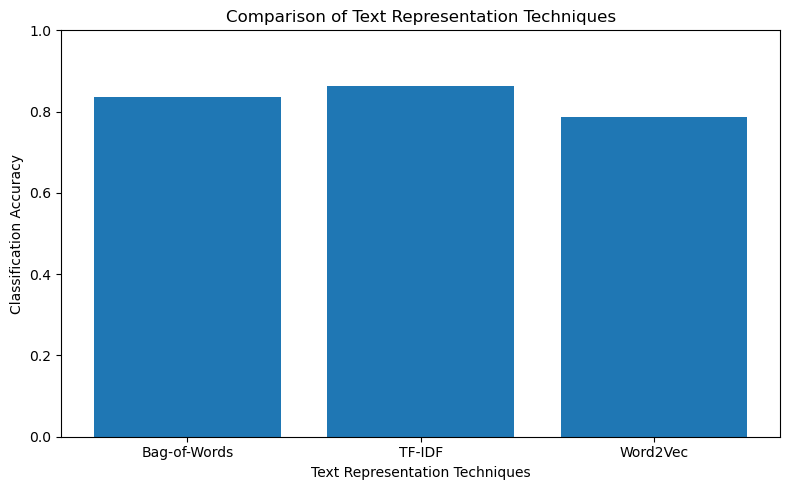

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.title("Comparison of Text Representation Techniques")
plt.xlabel("Text Representation Techniques")
plt.ylabel("Classification Accuracy")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()